# DeformBoundary-UNet — complete end-to-end notebook (train → cache → ensemble → quality-aware abstention → paper tables)

Runs everything from scratch (your earlier outputs are gone), **resumable**: every finished fold is cached in `outputs_v4/probs`, so after a Kaggle crash just re-run all cells and it continues.

**Pipeline**
1. Fixed split (seed 42): 15 % untouched hold-out test, the rest = 5-fold CV. Every CV image is predicted only by a model that never saw it (out-of-fold, OOF).
2. Model bank (all are the DeformBoundary-UNet family, so the paper stays about *your* model): quantum-hybrid ConvNeXt-T/320, **classical** ConvNeXt-T/320 (the quantum ablation — identical except the quantum gates), quantum-hybrid ConvNeXt-S/384.
3. Fixed training schedule + EMA (no checkpoint picking on tiny validation sets), flip TTA, Caruana weights / threshold / post-processing chosen on OOF only.
4. **Novel contribution:** predicted-quality abstention (per-image predicted Dice from ensemble disagreement + uncertainty + shape, cross-fitted on OOF) → risk–coverage analysis.
5. Quantum vs classical paired ablation, optional U-Net / Attention-U-Net baselines trained under the same protocol, optional reference evaluation of the public `BreastCancerAttentionUNet.h5`.

**Integrity rules:** test set evaluated once; nothing is tuned on it; headline number = all images (coverage 100 %); every selective number is printed with its coverage; nothing is simulated or hard-coded.

**Time (T4/P100):** roughly 3–4 h for the default bank. To shorten: delete one entry from `SPECS`, or set `folds=3`, or `epochs=30`.


In [15]:
# Cell 1 — Setup & configuration (Kaggle: Internet ON for pretrained weights, GPU ON, BUSI + attention-unet dataset as inputs)
!pip install -q timm "albumentations==1.4.24" opencv-python-headless scikit-image scikit-learn
import os, gc, copy, math, glob, json, time, random, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (distance_transform_edt, binary_fill_holes, binary_erosion, binary_dilation, label as ndlabel)
from scipy.stats import spearmanr, wilcoxon
from skimage.morphology import remove_small_objects
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import roc_auc_score
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); use_amp = device.type == "cuda"


def set_seed(s):
    random.seed(s); os.environ["PYTHONHASHSEED"] = str(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


CFG = dict(seed=42, test_size=0.15, include_normal=False,        # tumour-only protocol, identical split to v1/v2
           S0=320,                                               # common grid on which every model's probability map is stored
           folds=5, epochs=40, bs=8, workers=2,
           target_dice=0.90, target_iou=0.85, min_coverage=0.50,
           run_baselines=False, baseline_epochs=60, baseline_size=256,
           run_h5_reference=True,                                # evaluate the public Keras Attention-UNet .h5 (reference only, see cell 12)
           smoke=False, out_dir="outputs_v4",
           # ---- the public attention-unet weights dataset you added ----
           h5_dirs=["/kaggle/input/breast-cancer-segmentation-attention-unet"])

DEFAULTS = dict(encoder="convnext_tiny", size=320, quantum=True, n_qubits=4, q_layers=3,
                quantum_stages=("bottleneck", "dec3", "dec2", "dec1"), lr_enc=5e-5, lr_dec=4e-4, wd=1e-2, ema=0.995, warmup=2,
                w_bce=0.20, w_dice=0.40, w_focal=0.10, w_boundary_head=0.15, w_sdm=0.15, w_aux=0.30, sdm_ramp_epochs=15)
SPECS = [dict(name="DBU_Q_cnxt320", encoder="convnext_tiny",  size=320, quantum=True,  seed=11),
         dict(name="DBU_cnxt320",   encoder="convnext_tiny",  size=320, quantum=False, seed=12),   # classical twin = quantum ablation
         dict(name="DBU_Q_cnxs384", encoder="convnext_small", size=384, quantum=True,  seed=13)]
SPECS = [{**DEFAULTS, **s} for s in SPECS]
if CFG["smoke"]:
    CFG.update(S0=64, folds=2, epochs=2, bs=4, workers=0, baseline_epochs=2, baseline_size=64)
    for s in SPECS: s.update(size=64)
S0 = CFG["S0"]; set_seed(CFG["seed"])
PROB_DIR = os.path.join(CFG["out_dir"], "probs"); os.makedirs(PROB_DIR, exist_ok=True)


def find_data_dir():
    c = [os.environ.get("BUSI_DIR", ""),
         "/kaggle/input/datasets/sabahesaraki/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",
"/kaggle/input/datasets/sabahesaraki/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",
         "/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",
"/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",
            "/kaggle/input/breast-cancer-segmentation-attention-unet",
            "/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",
            "/kaggle/input/datasets/mdtasnimulhassankhan/busi-dataset/Dataset BUSI",
            "/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT",

         "/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT"] + glob.glob("/kaggle/input/**/Dataset_BUSI_with_GT", recursive=True)
    for p in c:
        if p and os.path.isdir(p): return p
    raise FileNotFoundError("BUSI dataset not found - add it via 'Add Input'.")


DATA_DIR = find_data_dir()
print(f"device={device} | torch {torch.__version__} | timm {timm.__version__} | AMP={use_amp}\nBUSI: {DATA_DIR}")
print("bank:", [(s["name"], s["encoder"], s["size"], "quantum" if s["quantum"] else "classical") for s in SPECS])


device=cuda | torch 2.11.0+cu130 | timm 1.0.30 | AMP=True
BUSI: /kaggle/input/datasets/sabahesaraki/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT
bank: [('DBU_Q_cnxt320', 'convnext_tiny', 320, 'quantum'), ('DBU_cnxt320', 'convnext_tiny', 320, 'classical'), ('DBU_Q_cnxs384', 'convnext_small', 384, 'quantum')]


In [16]:
# Cell 2 — Data, split, helpers (metrics, post-processing), near-duplicate audit

def collect_busi_files(data_dir, include_normal=False):
    cats = ["benign", "malignant"] + (["normal"] if include_normal else []); rec = []
    for cat in cats:
        d = os.path.join(data_dir, cat)
        if not os.path.isdir(d): continue
        files = sorted(os.listdir(d))
        for f in files:
            base, ext = os.path.splitext(f)
            if ext.lower() not in (".png", ".jpg", ".jpeg", ".bmp") or "_mask" in base.lower(): continue
            ms = [os.path.join(d, g) for g in files if g.lower().startswith(base.lower() + "_mask")]
            if cat != "normal" and not ms: continue
            rec.append({"img": os.path.join(d, f), "mask": "|".join(ms), "label": cat})
    return pd.DataFrame(rec)


def read_mask_union(mask_str):                      # several masks per image (_mask, _mask_1 ...) -> union
    mask = None
    for mp in mask_str.split("|"):
        if not mp: continue
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if mask is None: mask = np.zeros(m.shape, np.uint8)
        if m.shape != mask.shape: m = cv2.resize(m, (mask.shape[1], mask.shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = np.maximum(mask, ((m > 127) * 255).astype(np.uint8))
    return mask


df_all = collect_busi_files(DATA_DIR, CFG["include_normal"])
cv_df, test_df = train_test_split(df_all, test_size=CFG["test_size"], random_state=CFG["seed"], stratify=df_all["label"])
cv_df = cv_df.reset_index(drop=True); test_df = test_df.reset_index(drop=True)
print(df_all["label"].value_counts().to_dict(), "| CV pool:", len(cv_df), "| hold-out test:", len(test_df))

RAW = {r.img: (cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB), read_mask_union(r.mask)) for r in df_all.itertuples()}   # decoded once
gt_at = lambda df, S: np.stack([cv2.resize(RAW[k][1], (S, S), interpolation=cv2.INTER_NEAREST) > 127 for k in df["img"]]).astype(np.uint8)
OOF_MASK, TEST_MASK = gt_at(cv_df, S0), gt_at(test_df, S0)


def thumbs(df, s=32):
    out = []
    for k in df["img"]:
        g = cv2.resize(cv2.cvtColor(RAW[k][0], cv2.COLOR_RGB2GRAY), (s, s), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
        out.append((g - g.mean()) / (g.std() + 1e-6))
    return np.stack(out)


NEAR_DUP_TEST = (thumbs(test_df) @ thumbs(cv_df).T / 1024).max(1) > 0.98
print(f"near-duplicate audit (32x32 thumbnails, corr>0.98): {int(NEAR_DUP_TEST.sum())}/{len(test_df)} test images have a near-twin in the CV pool"
      + ("  -> reported with AND without them" if NEAR_DUP_TEST.any() else ""))


# ---------------- metrics / post-processing ----------------
def fast_metrics(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum((1, 2)).astype(np.float64); fp = (pred & ~gt).sum((1, 2)); fn = (~pred & gt).sum((1, 2))
    d = 2 * tp + fp + fn; u = tp + fp + fn
    return np.where(d > 0, 2 * tp / np.maximum(d, 1), 1.0), np.where(u > 0, tp / np.maximum(u, 1), 1.0)


def surface_hd95(pb, tb):
    if not pb.any() or not tb.any(): return float(np.hypot(*pb.shape))
    sp = pb & ~binary_erosion(pb); st = tb & ~binary_erosion(tb)
    return float(np.percentile(np.concatenate([distance_transform_edt(~st)[sp], distance_transform_edt(~sp)[st]]), 95))


def full_metrics(pred, gt):
    rows = []
    for pb, tb in zip(pred.astype(bool), gt.astype(bool)):
        tp = int((pb & tb).sum()); fp = int((pb & ~tb).sum()); fn = int((~pb & tb).sum()); tn = int((~pb & ~tb).sum())
        rows.append({"Dice": 2 * tp / max(1, 2 * tp + fp + fn), "IoU": tp / max(1, tp + fp + fn), "Precision": tp / max(1, tp + fp),
                     "Recall": tp / max(1, tp + fn), "Specificity": tn / max(1, tn + fp), "Accuracy": (tp + tn) / (tp + tn + fp + fn),
                     "HD95": surface_hd95(pb, tb)})
    return pd.DataFrame(rows)


def bootstrap_ci(x, n=2000, seed=0):
    x = np.asarray(x, float); r = np.random.default_rng(seed); b = [r.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return float(x.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


def postproc(b, min_frac=0.0015):
    b = binary_fill_holes(b); ms = int(min_frac * b.size)
    return remove_small_objects(b, min_size=ms) if ms > 0 and b.any() else b


# ---------------- dataset ----------------
def get_transform(size, augment):
    norm = [A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()]
    if not augment: return A.Compose([A.Resize(size, size)] + norm)
    return A.Compose([A.Resize(size, size), A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
        A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3),
        A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.15, rotate_limit=20, border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=0.6),
        A.OneOf([A.ElasticTransform(alpha=30, sigma=5, alpha_affine=0, p=1.0), A.GridDistortion(num_steps=5, distort_limit=0.2, p=1.0)], p=0.25),
        A.OneOf([A.GaussianBlur(blur_limit=3, p=1.0), A.MedianBlur(blur_limit=3, p=1.0)], p=0.15),
        A.RandomBrightnessContrast(0.2, 0.2, p=0.5), A.RandomGamma(gamma_limit=(80, 125), p=0.3), A.GaussNoise(var_limit=(5, 25), p=0.25)] + norm)


def signed_distance(m):
    m = m.astype(bool)
    if not m.any() or m.all(): return np.zeros(m.shape, np.float32)
    s = distance_transform_edt(~m) - distance_transform_edt(m); return (s / (np.abs(s).max() + 1e-8)).astype(np.float32)


class SegDS(Dataset):
    def __init__(self, df, size, augment=False):
        self.keys = df["img"].tolist(); self.augment = augment; self.tf = get_transform(size, augment)
    def __len__(self): return len(self.keys)
    def __getitem__(self, i):
        img, mask = RAW[self.keys[i]]; a = self.tf(image=img, mask=mask); m = (a["mask"] > 127).float().unsqueeze(0)
        sdm = torch.from_numpy(signed_distance(m[0].numpy())).unsqueeze(0) if self.augment else torch.zeros_like(m)
        return a["image"], m, sdm


def make_loader(df, size, augment=False, shuffle=False, drop_last=False):
    return DataLoader(SegDS(df, size, augment), batch_size=CFG["bs"], shuffle=shuffle, drop_last=drop_last, num_workers=CFG["workers"],
                      pin_memory=(device.type == "cuda"), persistent_workers=CFG["workers"] > 0)


{'benign': 437, 'malignant': 210} | CV pool: 549 | hold-out test: 98
near-duplicate audit (32x32 thumbnails, corr>0.98): 22/98 test images have a near-twin in the CV pool  -> reported with AND without them


In [17]:
# Cell 3 — Quantum module: differentiable variational quantum circuit (exact state-vector simulation in PyTorch)
# No extra libraries needed. Circuit: data re-uploading, RY/RZ rotations, ring of CNOTs, <Z> read-out.

def _ry(a):                      # a: (...,)  ->  (...,2,2) complex
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    m = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    return torch.complex(m, torch.zeros_like(m))


def _rz(a):
    e = torch.complex(torch.cos(a / 2), -torch.sin(a / 2))   # e^{-ia/2}
    z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)


def _apply_1q(state, U, q):
    """state: (B,2,...,2) complex; U: (2,2) or (B,2,2); acts on qubit q."""
    B = state.shape[0]
    s = state.movedim(q + 1, -1); shp = s.shape
    s = s.reshape(B, -1, 2)
    s = s @ U.transpose(-1, -2) if U.dim() == 2 else torch.einsum("bij,bkj->bki", U, s)
    return s.reshape(shp).movedim(-1, q + 1)


def _cnot(state, c, t):
    s0, s1 = state.select(c + 1, 0), state.select(c + 1, 1)
    ta = t + 1 if t < c else t                      # target axis after removing control axis
    return torch.stack([s0, s1.flip(ta)], dim=c + 1)


class VariationalQuantumCircuit(nn.Module):
    def __init__(self, n_qubits=4, n_layers=3):
        super().__init__()
        self.n, self.L = n_qubits, n_layers
        self.theta = nn.Parameter(0.5 * torch.randn(n_layers, n_qubits, 2))

    def forward(self, x):                           # x: (B, n) rotation angles -> (B, n) expectations <Z_q> in [-1,1]
        B = x.shape[0]
        st = torch.zeros(B, 2 ** self.n, dtype=torch.complex64, device=x.device)
        st[:, 0] = 1.0
        st = st.view(B, *([2] * self.n))
        for l in range(self.L):
            for q in range(self.n):
                st = _apply_1q(st, _ry(x[:, q]), q)               # data (re-)uploading
                st = _apply_1q(st, _ry(self.theta[l, q, 0]), q)   # trainable rotations
                st = _apply_1q(st, _rz(self.theta[l, q, 1]), q)
            for q in range(self.n):                              # entanglement (ring)
                st = _cnot(st, q, (q + 1) % self.n)
        p = st.real ** 2 + st.imag ** 2
        z = []
        for q in range(self.n):
            pq = p.movedim(q + 1, -1).reshape(B, -1, 2).sum(1)
            z.append(pq[:, 0] - pq[:, 1])
        return torch.stack(z, -1)


class QuantumChannelGate(nn.Module):
    """Hybrid quantum-classical channel attention:
    GAP -> Linear -> angles -> VQC -> <Z> -> Linear -> tanh gate;  out = x * (1 + gate)."""
    def __init__(self, channels, n_qubits=4, n_layers=3):
        super().__init__()
        self.pre = nn.Linear(channels, n_qubits)
        self.vqc = VariationalQuantumCircuit(n_qubits, n_layers)
        self.post = nn.Linear(n_qubits, channels)
        nn.init.normal_(self.post.weight, std=0.02); nn.init.zeros_(self.post.bias)

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            g = x.float().mean(dim=(2, 3))
            ang = math.pi * torch.tanh(self.pre(g))
            z = self.vqc(ang)
            gate = torch.tanh(self.post(z)).unsqueeze(-1).unsqueeze(-1)
        return x * (1.0 + gate).to(x.dtype)


# --- sanity checks of the simulator (physics) ---
_vqc = VariationalQuantumCircuit(4, 2)
_x = torch.rand(5, 4) * math.pi
assert _vqc(_x).abs().max() <= 1.0 + 1e-5
_s = torch.zeros(1, 2, dtype=torch.complex64); _s[0, 0] = 1
_s = _apply_1q(_s, _ry(torch.tensor([math.pi])), 0)            # RY(pi)|0> = |1>  ->  <Z> = -1
assert abs(float((_s.real ** 2 + _s.imag ** 2)[0, 0] - (_s.real ** 2 + _s.imag ** 2)[0, 1]) + 1) < 1e-5
print("Quantum simulator checks passed | trainable VQC params:", sum(p.numel() for p in _vqc.parameters()))


Quantum simulator checks passed | trainable VQC params: 16


In [18]:
# Cell 4 — Novel model: DeformBoundary-UNet (+ optional quantum gates)
# Novel parts: DBAM (deformable boundary attention), BEM (Sobel boundary enhancement),
#              FGM (FFT frequency gating), supervised boundary head, deep supervision,
#              hybrid Quantum Channel Gates (QCG).

def create_encoder(name):
    kw = dict(features_only=True, out_indices=(0, 1, 2, 3))
    for extra in (dict(pretrained=True, drop_path_rate=0.1), dict(pretrained=True)):
        try:
            enc = timm.create_model(name, **extra, **kw); enc.pretrained_loaded = True
            return enc
        except Exception as e:
            err = e
    print("!!! WARNING: pretrained weights NOT available (", str(err)[:80], ") -> random init. "
          "Turn Internet ON in Kaggle, otherwise results will be much worse.")
    enc = timm.create_model(name, pretrained=False, **kw); enc.pretrained_loaded = False
    return enc


class DeformableBoundaryAttention(nn.Module):
    def __init__(self, ch, heads=4, points=4):
        super().__init__()
        assert ch % heads == 0
        self.h, self.p, self.hd = heads, points, ch // heads
        self.offset = nn.Sequential(nn.Conv2d(ch, ch // 4, 3, padding=1), nn.GELU(),
                                    nn.Conv2d(ch // 4, heads * points * 2, 1))
        self.attn = nn.Sequential(nn.Conv2d(ch, ch // 4, 3, padding=1), nn.GELU(),
                                  nn.Conv2d(ch // 4, heads * points, 1))
        self.value = nn.Conv2d(ch, ch, 1)
        self.out = nn.Sequential(nn.Conv2d(ch, ch, 1), nn.GroupNorm(8, ch))
        self.norm = nn.GroupNorm(8, ch)
        nn.init.zeros_(self.offset[-1].weight); nn.init.zeros_(self.offset[-1].bias)

    def forward(self, x):
        B, C, H, W = x.shape
        xn = self.norm(x)
        off = self.offset(xn).view(B, self.h, self.p, 2, H, W).permute(0, 1, 2, 4, 5, 3)
        att = torch.softmax(self.attn(xn).view(B, self.h, self.p, H, W), dim=2)
        gy, gx = torch.meshgrid(torch.linspace(-1, 1, H, device=x.device, dtype=x.dtype),
                                torch.linspace(-1, 1, W, device=x.device, dtype=x.dtype), indexing="ij")
        base = torch.stack([gx, gy], -1).view(1, 1, 1, H, W, 2)
        grid = (base + torch.tanh(off) * 0.25).reshape(B * self.h * self.p, H, W, 2)
        v = self.value(xn).view(B, self.h, 1, self.hd, H, W).expand(B, self.h, self.p, self.hd, H, W)
        v = v.reshape(B * self.h * self.p, self.hd, H, W)
        s = F.grid_sample(v, grid.to(v.dtype), mode="bilinear", padding_mode="zeros", align_corners=False)
        s = s.view(B, self.h, self.p, self.hd, H, W)
        return x + self.out((s * att.unsqueeze(3)).sum(2).reshape(B, C, H, W))


class BoundaryEnhancementModule(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.edge = nn.Sequential(nn.Conv2d(ch, max(ch // 4, 4), 3, padding=1), nn.GELU(),
                                  nn.Conv2d(max(ch // 4, 4), 1, 1), nn.Sigmoid())
        self.enh = nn.Sequential(nn.Conv2d(ch + 1, ch, 3, padding=1), nn.GroupNorm(8, ch), nn.GELU(),
                                 nn.Conv2d(ch, ch, 1))
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32)
        self.register_buffer("kx", kx.view(1, 1, 3, 3)); self.register_buffer("ky", kx.t().contiguous().view(1, 1, 3, 3))

    def forward(self, x):
        m = x.mean(1, keepdim=True)
        e = torch.sqrt(F.conv2d(m, self.kx.to(m.dtype), padding=1) ** 2 +
                       F.conv2d(m, self.ky.to(m.dtype), padding=1) ** 2 + 1e-8)
        e = e / (e.amax(dim=(2, 3), keepdim=True) + 1e-8)
        return x + self.enh(torch.cat([x, e * self.edge(x)], 1))


class FrequencyGatingModule(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.fg = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(ch, ch // 4), nn.GELU(),
                                nn.Linear(ch // 4, ch), nn.Sigmoid())
        self.sg = nn.Sequential(nn.Conv2d(ch, ch // 4, 3, padding=1), nn.GELU(),
                                nn.Conv2d(ch // 4, ch, 3, padding=1), nn.Sigmoid())

    def forward(self, x):
        B, C, H, W = x.shape
        with torch.autocast(device_type=x.device.type, enabled=False):
            xf = x.float()
            spec = torch.fft.rfft2(xf, norm="ortho")
            xr = torch.fft.irfft2(spec * self.fg(xf).view(B, C, 1, 1), s=(H, W), norm="ortho")
        g = self.sg(x)
        return xr.to(x.dtype) * g + x * (1 - g)


class DeformBoundaryBlock(nn.Module):
    def __init__(self, ch, heads=4, points=4):
        super().__init__()
        self.da = DeformableBoundaryAttention(ch, heads, points)
        self.bem = BoundaryEnhancementModule(ch)
        self.fgm = FrequencyGatingModule(ch)
        self.mlp = nn.Sequential(nn.Conv2d(ch, ch * 2, 1), nn.GELU(), nn.Dropout2d(0.1),
                                 nn.Conv2d(ch * 2, ch, 1), nn.GroupNorm(8, ch))

    def forward(self, x):
        x = self.fgm(self.bem(self.da(x)))
        return x + self.mlp(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, heads, points, qgate=None):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, 2)
        self.c1 = nn.Sequential(nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1), nn.GroupNorm(8, out_ch), nn.GELU())
        self.blk = DeformBoundaryBlock(out_ch, heads, points)
        self.c2 = nn.Sequential(nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.GroupNorm(8, out_ch), nn.GELU())
        self.q = qgate if qgate is not None else nn.Identity()

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
        return self.q(self.c2(self.blk(self.c1(torch.cat([x, skip], 1)))))


class DeformBoundaryUNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        qs = set(cfg["quantum_stages"]) if cfg["quantum"] else set()
        mk = lambda name, ch: QuantumChannelGate(ch, cfg["n_qubits"], cfg["q_layers"]) if name in qs else None
        self.encoder = create_encoder(cfg["encoder"])
        e = self.encoder.feature_info.channels()
        self.bottleneck = nn.Sequential(
            nn.Conv2d(e[3], 512, 3, padding=1), nn.GroupNorm(8, 512), nn.GELU(),
            DeformBoundaryBlock(512, 8, 4), DeformBoundaryBlock(512, 8, 4),
            mk("bottleneck", 512) or nn.Identity())
        self.dec3 = DecoderBlock(512, e[2], 256, 8, 3, mk("dec3", 256))
        self.dec2 = DecoderBlock(256, e[1], 128, 4, 3, mk("dec2", 128))
        self.dec1 = DecoderBlock(128, e[0], 64, 4, 2, mk("dec1", 64))
        self.head = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.GroupNorm(8, 32), nn.GELU(),
                                  BoundaryEnhancementModule(32), nn.Conv2d(32, 1, 1))
        self.bhead = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.GroupNorm(8, 32), nn.GELU(),
                                   nn.Conv2d(32, 1, 1))
        self.aux3 = nn.Conv2d(256, 1, 1); self.aux2 = nn.Conv2d(128, 1, 1)

    def forward(self, x):
        size = x.shape[2:]
        up = lambda t: F.interpolate(t, size=size, mode="bilinear", align_corners=False)
        s1, s2, s3, s4 = self.encoder(x)
        d3 = self.dec3(self.bottleneck(s4), s3)
        d2 = self.dec2(d3, s2)
        d1 = self.dec1(d2, s1)
        seg = up(self.head(d1))
        if self.training:
            return seg, up(self.bhead(d1)), up(self.aux2(d2)), up(self.aux3(d3))
        return seg


for _sp in SPECS[:2]:
    _m = DeformBoundaryUNet(_sp).to(device).eval()
    with torch.no_grad(): _o = _m(torch.randn(2, 3, _sp["size"], _sp["size"], device=device))
    print(f"{_sp['name']:15s} OK -> {tuple(_o.shape)} | {sum(p.numel() for p in _m.parameters())/1e6:.1f} M params | quantum gates: "
          f"{sum(isinstance(m, QuantumChannelGate) for m in _m.modules())} | pretrained: {_m.encoder.pretrained_loaded}")
    del _m, _o; gc.collect(); torch.cuda.empty_cache()


DBU_Q_cnxt320   OK -> (2, 1, 320, 320) | 51.8 M params | quantum gates: 4 | pretrained: True
DBU_cnxt320     OK -> (2, 1, 320, 320) | 51.8 M params | quantum gates: 0 | pretrained: True


In [19]:
# Cell 5 — Loss, EMA, fixed-schedule training, TTA inference, resumable out-of-fold runner

class CompoundSegLoss(nn.Module):
    def __init__(self, c, gamma=2.0, alpha=0.5):
        super().__init__(); self.c, self.gamma, self.alpha, self.sdm_scale = c, gamma, alpha, 0.0
    @staticmethod
    def dice(p, t):
        inter = (p * t).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + t.sum((1, 2, 3)); return (1 - (2 * inter + 1) / (den + 1)).mean()
    def focal(self, lg, t):
        ce = F.binary_cross_entropy_with_logits(lg, t, reduction="none"); p = torch.sigmoid(lg); pt = torch.where(t == 1, p, 1 - p)
        return (torch.where(t == 1, self.alpha, 1 - self.alpha) * (1 - pt) ** self.gamma * ce).mean()
    def seg_terms(self, lg, t):
        c = self.c; return c["w_bce"] * F.binary_cross_entropy_with_logits(lg, t) + c["w_dice"] * self.dice(torch.sigmoid(lg), t) + c["w_focal"] * self.focal(lg, t)
    def forward(self, outs, t, sdm):
        seg, bnd, a2, a3 = [o.float() for o in outs]; t = t.float(); c = self.c
        loss = self.seg_terms(seg, t) + c["w_aux"] * 0.5 * (self.seg_terms(a2, t) + self.seg_terms(a3, t))
        bt = (t - (-F.max_pool2d(-t, 5, 1, 2))).clamp(0, 1); bp = torch.sigmoid(bnd)
        b_dice = 1 - (2 * (bp * bt).sum() + 1) / (bp.sum() + bt.sum() + 1)
        loss = loss + c["w_boundary_head"] * (0.5 * F.binary_cross_entropy_with_logits(bnd, bt) + 0.5 * b_dice)
        return loss + self.sdm_scale * c["w_sdm"] * (torch.sigmoid(seg) * sdm.float()).mean() * 4.0


class ModelEMA:
    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval(); self.decay, self.step = decay, 0
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.step += 1; d = min(self.decay, (1 + self.step) / (10 + self.step))
        for (k, e), (_, v) in zip(self.m.state_dict().items(), model.state_dict().items()):
            e.mul_(d).add_(v.detach(), alpha=1 - d) if e.dtype.is_floating_point else e.copy_(v)


@torch.no_grad()
def monitor_dice(model, loader):                       # PRINTED ONLY - never used for any decision
    model.eval(); d = []
    for x, t, _ in loader:
        p = (torch.sigmoid(model(x.to(device)).float()) > 0.5).float(); t = t.to(device)
        d.append(((2 * (p * t).sum((1, 2, 3)) + 1e-6) / (p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + 1e-6)).cpu())
    return float(torch.cat(d).mean())


def fit(spec, tr_df, mon_df, tag):
    set_seed(spec["seed"]); model = DeformBoundaryUNet(spec).to(device); crit = CompoundSegLoss(spec)
    enc = [p for n, p in model.named_parameters() if n.startswith("encoder")]; dec = [p for n, p in model.named_parameters() if not n.startswith("encoder")]
    opt = torch.optim.AdamW([{"params": enc, "lr": spec["lr_enc"]}, {"params": dec, "lr": spec["lr_dec"]}], weight_decay=spec["wd"])
    E, W = CFG["epochs"], spec["warmup"]
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / W if e < W else 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, E - W))))
    try: scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    ema = ModelEMA(model, spec["ema"]); tr_ld = make_loader(tr_df, spec["size"], True, True, True); mon_ld = make_loader(mon_df, spec["size"])
    for ep in range(E):
        model.train(); crit.sdm_scale = min(1.0, ep / max(1, spec["sdm_ramp_epochs"])); run = n = 0
        for x, m, sdm in tr_ld:
            x, m, sdm = x.to(device, non_blocking=True), m.to(device), sdm.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp): outs = model(x)
            loss = crit(outs, m, sdm); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); ema.update(model); run += loss.item(); n += 1
        sched.step()
        if (ep + 1) % 5 == 0 or ep == E - 1:
            print(f"[{tag}] ep {ep+1:02d}/{E} loss {run/max(1,n):.4f} | held-out Dice@0.5 (EMA, info only) {monitor_dice(ema.m, mon_ld):.4f}", flush=True)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ema.m


@torch.no_grad()
def predict_probs(model, loader):                        # 4-way flip TTA, returned on the common S0 grid
    model.eval(); out = []
    for x, _, _ in loader:
        x = x.to(device)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            p = torch.sigmoid(model(x).float()) + torch.flip(torch.sigmoid(model(torch.flip(x, [3])).float()), [3]) \
                + torch.flip(torch.sigmoid(model(torch.flip(x, [2])).float()), [2]) + torch.flip(torch.sigmoid(model(torch.flip(x, [2, 3])).float()), [2, 3])
        out.append(F.interpolate(p / 4.0, size=(S0, S0), mode="bilinear", align_corners=False)[:, 0].cpu().numpy().astype(np.float16))
    return np.concatenate(out)


def run_cv(spec):
    """Every CV image is predicted ONLY by a fold model that never saw it; the hold-out test set is predicted by all fold models (averaged).
    Finished folds are cached -> re-running the notebook resumes where it stopped."""
    tag, size = spec["name"], spec["size"]; final = os.path.join(PROB_DIR, f"{tag}.npz")
    if os.path.exists(final):
        z = np.load(final); print(f"{tag}: finished predictions found"); return dict(oof=z["oof"], test=z["test"])
    skf = StratifiedKFold(CFG["folds"], shuffle=True, random_state=spec["seed"])
    oof = np.zeros((len(cv_df), S0, S0), np.float16); tests = []; test_ld = make_loader(test_df, size)
    for fold, (tr, va) in enumerate(skf.split(cv_df, cv_df["label"])):
        part = os.path.join(PROB_DIR, f"{tag}_fold{fold}.npz")
        if os.path.exists(part):
            z = np.load(part); oof[va] = z["oof"]; tests.append(z["test"]); print(f"{tag} fold {fold}: loaded from cache"); continue
        tr_df, va_df = cv_df.iloc[tr].reset_index(drop=True), cv_df.iloc[va].reset_index(drop=True)
        print(f"\n===== {tag} | fold {fold}: train {len(tr_df)} | held-out {len(va_df)} =====", flush=True); t0 = time.time()
        model = fit(spec, tr_df, va_df, f"{tag} f{fold}")
        P = predict_probs(model, make_loader(va_df, size)); T = predict_probs(model, test_ld)
        oof[va] = P; tests.append(T); np.savez_compressed(part, oof=P, test=T)
        print(f"{tag} fold {fold}: held-out Dice@0.5 (TTA) {fast_metrics(P > 0.5, OOF_MASK[va])[0].mean():.4f} | {(time.time()-t0)/60:.1f} min", flush=True)
        del model; gc.collect(); torch.cuda.empty_cache()
    test = np.mean([t.astype(np.float32) for t in tests], 0).astype(np.float16); np.savez_compressed(final, oof=oof, test=test)
    return dict(oof=oof, test=test)


In [20]:
# Cell 6 — Train / load the model bank (this is the long cell; resumable)
BANK = {}; t0 = time.time()
for spec in SPECS:
    BANK[spec["name"]] = run_cv(spec)
    d_o = fast_metrics(BANK[spec["name"]]["oof"] > 0.5, OOF_MASK)[0].mean(); d_t = fast_metrics(BANK[spec["name"]]["test"] > 0.5, TEST_MASK)[0].mean()
    print(f"--> {spec['name']}: OOF Dice@0.5 {d_o:.4f} | test Dice@0.5 {d_t:.4f}\n", flush=True)
print(f"bank ready in {(time.time()-t0)/60:.1f} min -> probabilities cached in {PROB_DIR}")



===== DBU_Q_cnxt320 | fold 0: train 439 | held-out 110 =====
[DBU_Q_cnxt320 f0] ep 05/40 loss 0.2917 | held-out Dice@0.5 (EMA, info only) 0.7783
[DBU_Q_cnxt320 f0] ep 10/40 loss 0.2295 | held-out Dice@0.5 (EMA, info only) 0.8100
[DBU_Q_cnxt320 f0] ep 15/40 loss 0.1906 | held-out Dice@0.5 (EMA, info only) 0.8238
[DBU_Q_cnxt320 f0] ep 20/40 loss 0.1722 | held-out Dice@0.5 (EMA, info only) 0.8288
[DBU_Q_cnxt320 f0] ep 25/40 loss 0.1574 | held-out Dice@0.5 (EMA, info only) 0.8243
[DBU_Q_cnxt320 f0] ep 30/40 loss 0.1404 | held-out Dice@0.5 (EMA, info only) 0.8316
[DBU_Q_cnxt320 f0] ep 35/40 loss 0.1359 | held-out Dice@0.5 (EMA, info only) 0.8302
[DBU_Q_cnxt320 f0] ep 40/40 loss 0.1340 | held-out Dice@0.5 (EMA, info only) 0.8291
DBU_Q_cnxt320 fold 0: held-out Dice@0.5 (TTA) 0.8336 | 12.2 min

===== DBU_Q_cnxt320 | fold 1: train 439 | held-out 110 =====
[DBU_Q_cnxt320 f1] ep 05/40 loss 0.3065 | held-out Dice@0.5 (EMA, info only) 0.8036
[DBU_Q_cnxt320 f1] ep 10/40 loss 0.2407 | held-out Dice@

model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

[DBU_Q_cnxs384 f0] ep 05/40 loss 0.2901 | held-out Dice@0.5 (EMA, info only) 0.8200
[DBU_Q_cnxs384 f0] ep 10/40 loss 0.2132 | held-out Dice@0.5 (EMA, info only) 0.8361
[DBU_Q_cnxs384 f0] ep 15/40 loss 0.1867 | held-out Dice@0.5 (EMA, info only) 0.8536
[DBU_Q_cnxs384 f0] ep 20/40 loss 0.1618 | held-out Dice@0.5 (EMA, info only) 0.8555
[DBU_Q_cnxs384 f0] ep 25/40 loss 0.1431 | held-out Dice@0.5 (EMA, info only) 0.8559
[DBU_Q_cnxs384 f0] ep 30/40 loss 0.1324 | held-out Dice@0.5 (EMA, info only) 0.8564
[DBU_Q_cnxs384 f0] ep 35/40 loss 0.1207 | held-out Dice@0.5 (EMA, info only) 0.8555
[DBU_Q_cnxs384 f0] ep 40/40 loss 0.1231 | held-out Dice@0.5 (EMA, info only) 0.8565
DBU_Q_cnxs384 fold 0: held-out Dice@0.5 (TTA) 0.8629 | 18.6 min

===== DBU_Q_cnxs384 | fold 1: train 439 | held-out 110 =====
[DBU_Q_cnxs384 f1] ep 05/40 loss 0.2760 | held-out Dice@0.5 (EMA, info only) 0.8054
[DBU_Q_cnxs384 f1] ep 10/40 loss 0.2255 | held-out Dice@0.5 (EMA, info only) 0.8200
[DBU_Q_cnxs384 f1] ep 15/40 loss 0

In [21]:
# Cell 7 — Caruana ensemble weights, threshold and post-processing: chosen on OOF only, then frozen

def caruana(names, key="oof", iters=20, thr=0.5):
    arr = {n: BANK[n][key].astype(np.float32) for n in names}; cnt = {n: 0 for n in names}; acc = None
    for it in range(iters):
        best = (-1, None)
        for n in names:
            cand = arr[n] if acc is None else acc + arr[n]
            d = fast_metrics(cand / (it + 1) > thr, OOF_MASK)[0].mean()
            if d > best[0]: best = (d, n)
        acc = arr[best[1]].copy() if acc is None else acc + arr[best[1]]; cnt[best[1]] += 1
    return {n: c / iters for n, c in cnt.items()}


def blend(w, key): return sum(v * BANK[n][key].astype(np.float32) for n, v in w.items() if v > 0).astype(np.float32)


STAGE1 = list(BANK)                                       # independent models -> their disagreement = epistemic uncertainty
W2 = caruana(STAGE1); BASE_oof, BASE_test = blend(W2, "oof"), blend(W2, "test")
THR = float(max(np.arange(0.30, 0.71, 0.05), key=lambda t: fast_metrics(BASE_oof > t, OOF_MASK)[0].mean()))      # OOF only
DEC_oof, DEC_test = np.stack([postproc(p > THR) for p in BASE_oof]), np.stack([postproc(p > THR) for p in BASE_test])
M_oof, M_test = full_metrics(DEC_oof, OOF_MASK), full_metrics(DEC_test, TEST_MASK)
M_oof["label"], M_test["label"] = cv_df["label"].values, test_df["label"].values
print("weights:", {k: round(v, 2) for k, v in W2.items()}, f"| threshold {THR:.2f} (OOF-selected)")
print(f"ALL-IMAGES  OOF : Dice {M_oof.Dice.mean():.4f} | IoU {M_oof.IoU.mean():.4f}")
print(f"ALL-IMAGES  TEST: Dice {M_test.Dice.mean():.4f} | IoU {M_test.IoU.mean():.4f} | HD95 {M_test.HD95.mean():.1f}")
print("per class (test):\n", M_test.groupby("label")[["Dice", "IoU", "HD95"]].mean().round(4).to_string())
print(f"images with Dice<0.5: OOF {(M_oof.Dice<0.5).sum()}/{len(M_oof)} | test {(M_test.Dice<0.5).sum()}/{len(M_test)}   "
      f"(non-failure mean Dice OOF {M_oof.Dice[M_oof.Dice>=0.5].mean():.4f} -> ceiling if every failure were fixed ≈ "
      f"{(M_oof.Dice.where(M_oof.Dice>=0.5, M_oof.Dice[M_oof.Dice>=0.5].median())).mean():.4f})")


weights: {'DBU_Q_cnxt320': 0.15, 'DBU_cnxt320': 0.55, 'DBU_Q_cnxs384': 0.3} | threshold 0.50 (OOF-selected)
ALL-IMAGES  OOF : Dice 0.8398 | IoU 0.7645
ALL-IMAGES  TEST: Dice 0.8496 | IoU 0.7801 | HD95 29.2
per class (test):
              Dice     IoU     HD95
label                             
benign     0.8846  0.8224  18.3740
malignant  0.7774  0.6927  51.5007
images with Dice<0.5: OOF 39/549 | test 8/98   (non-failure mean Dice OOF 0.8908 -> ceiling if every failure were fixed ≈ 0.8933)


In [22]:
# Cell 9— Predicted-Quality Estimator: per-image features -> predicted Dice (cross-fitted on OOF)
# NOVEL PART.  Ground truth is used ONLY as the regression target, and only on OOF images.

MEMBERS = STAGE1                                    # independent models -> disagreement = epistemic uncertainty
FEAT_GROUPS = {
    "agreement":  ["agree_mean", "agree_min", "area_cv", "member_dice_min", "prob_std_in"],
    "confidence": ["mean_prob_in", "pmax", "unc_frac", "ent_in", "ent_band", "ent_global"],
    "shape":      ["area_frac", "n_comp", "largest_frac", "border_touch", "cy", "cx", "solidity", "empty"],
}
FEATS = sum(FEAT_GROUPS.values(), [])


def _entropy(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return -(p * np.log(p) + (1 - p) * np.log(1 - p))


def _dice_b(a, b):
    s = a.sum() + b.sum(); return 1.0 if s == 0 else 2.0 * (a & b).sum() / s


def quality_features(Pm, Pc, B):
    """Pm (M,H,W) member probs, Pc (H,W) consensus prob, B (H,W) decoded mask  ->  dict of scalars."""
    H, W = B.shape; area = float(B.sum()); f = {}
    ms = [p > 0.5 for p in Pm]; ious = []
    for a in range(len(ms)):
        for b in range(a + 1, len(ms)):
            u = (ms[a] | ms[b]).sum(); ious.append((ms[a] & ms[b]).sum() / u if u else 1.0)
    f["agree_mean"], f["agree_min"] = float(np.mean(ious)), float(np.min(ious))
    ar = np.array([m.sum() for m in ms], float); f["area_cv"] = float(ar.std() / (ar.mean() + 1))
    f["member_dice_min"] = float(min(_dice_b(m, B) for m in ms))
    Pstd = Pm.std(0); reg = B | np.any(ms, 0)
    f["prob_std_in"] = float(Pstd[reg].mean()) if reg.any() else 0.0
    f["mean_prob_in"] = float(Pc[B].mean()) if B.any() else 0.0
    f["pmax"] = float(Pc.max())
    f["unc_frac"] = float(((Pc > 0.2) & (Pc < 0.8)).sum() / max(area, 1.0))
    E = _entropy(Pc); f["ent_in"] = float(E[B].mean()) if B.any() else 0.0
    band = binary_dilation(B, iterations=3) & ~binary_erosion(B, iterations=3) if B.any() else B
    f["ent_band"] = float(E[band].mean()) if band.any() else 0.0
    f["ent_global"] = float(E.mean())
    f["area_frac"] = area / (H * W)
    lab, n = ndlabel(B); f["n_comp"] = float(n)
    f["largest_frac"] = float(np.bincount(lab.ravel())[1:].max() / area) if n else 0.0
    f["border_touch"] = float((B[0].any() or B[-1].any() or B[:, 0].any() or B[:, -1].any()))
    if B.any():
        ys, xs = np.nonzero(B); f["cy"], f["cx"] = float(ys.mean() / H - 0.5), float(xs.mean() / W - 0.5)
        hull_area = (ys.max() - ys.min() + 1) * (xs.max() - xs.min() + 1); f["solidity"] = float(area / hull_area)
    else:
        f["cy"] = f["cx"] = f["solidity"] = 0.0
    f["empty"] = float(not B.any())
    return f


def feature_table(key, P, DEC):
    Pm = [BANK[n][key] for n in MEMBERS]
    return pd.DataFrame([quality_features(np.stack([m[i].astype(np.float32) for m in Pm]), P[i], DEC[i]) for i in range(len(P))])


t0 = time.time()
X_oof, X_test = feature_table("oof", BASE_oof, DEC_oof), feature_table("test", BASE_test, DEC_test)
y_oof, y_test = M_oof["Dice"].values, M_test["Dice"].values
print(f"features: {X_oof.shape[1]} per image | extracted in {time.time()-t0:.0f}s")


def safe_auc(y, s):
    y = np.asarray(y)
    return float(roc_auc_score(y, s)) if 0 < y.sum() < len(y) else float("nan")


def make_gbr(seed=0):
    return GradientBoostingRegressor(n_estimators=250, max_depth=2, learning_rate=0.04, subsample=0.8,
                                     min_samples_leaf=8, random_state=seed)


def crossfit(X, y, cols, n_rep=5, k=5):
    """Honest OOF prediction of Dice: every image is predicted by a regressor that never saw its label (repeated K-fold)."""
    pred = np.zeros(len(y)); 
    for r in range(n_rep):
        for tr, va in KFold(k, shuffle=True, random_state=100 + r).split(X):
            pred[va] += make_gbr(r).fit(X.iloc[tr][cols], y[tr]).predict(X.iloc[va][cols]) / n_rep
    return pred


def risk_curve(score, dice):
    o = np.argsort(-score, kind="stable"); cs = np.cumsum(dice[o]) / np.arange(1, len(o) + 1)
    return cs                                               # selective Dice when keeping the top-k ranked images


def aurc(score, dice):
    return float(np.mean(1 - risk_curve(score, dice)))      # lower is better


fail_oof = (y_oof < 0.5).astype(int)
qhat_oof = crossfit(X_oof, y_oof, FEATS)
print(f"\nquality estimator (cross-fitted on OOF, n={len(y_oof)}):  Spearman(q̂, true Dice) = {spearmanr(qhat_oof, y_oof)[0]:.3f} | "
      f"failure-detection AUROC (Dice<0.5) = {safe_auc(fail_oof, -qhat_oof):.3f}")

# ---- ablation of feature groups + simple baselines (what carries the signal?) ----
rows = []
simple = {"random ranking": np.random.default_rng(0).random(len(y_oof)), "mean prob in lesion": X_oof["mean_prob_in"].values,
          "model agreement (IoU)": X_oof["agree_mean"].values, "-entropy in lesion": -X_oof["ent_in"].values}
for nm, sc in simple.items():
    rows.append(dict(score=nm, AUROC_fail=safe_auc(fail_oof, -sc), AURC=aurc(sc, y_oof)))
for g in FEAT_GROUPS:
    q = crossfit(X_oof, y_oof, FEAT_GROUPS[g], n_rep=2); rows.append(dict(score=f"GBR on [{g}]", AUROC_fail=safe_auc(fail_oof, -q), AURC=aurc(q, y_oof)))
rows.append(dict(score="GBR on ALL features (ours)", AUROC_fail=safe_auc(fail_oof, -qhat_oof), AURC=aurc(qhat_oof, y_oof)))
rows.append(dict(score="oracle (true Dice)", AUROC_fail=1.0, AURC=aurc(y_oof, y_oof)))
ABL = pd.DataFrame(rows).round(4); print("\n" + ABL.to_string(index=False))

# final estimator: fit on ALL OOF, applied once to the test set
GBRS = [make_gbr(s).fit(X_oof[FEATS], y_oof) for s in range(5)]
qhat_test = np.mean([g.predict(X_test[FEATS]) for g in GBRS], 0)
print(f"\nTEST: Spearman(q̂, true Dice) = {spearmanr(qhat_test, y_test)[0]:.3f} | failure AUROC = {safe_auc((y_test < 0.5).astype(int), -qhat_test):.3f}")
imp = pd.Series(np.mean([g.feature_importances_ for g in GBRS], 0), index=FEATS).sort_values(ascending=False)
print("top features:", ", ".join(f"{k} {v:.2f}" for k, v in imp.head(6).items()))


features: 19 per image | extracted in 5s

quality estimator (cross-fitted on OOF, n=549):  Spearman(q̂, true Dice) = 0.756 | failure-detection AUROC (Dice<0.5) = 0.843

                     score  AUROC_fail   AURC
            random ranking      0.4791 0.1658
       mean prob in lesion      0.8715 0.0735
     model agreement (IoU)      0.8739 0.0734
        -entropy in lesion      0.8434 0.0863
        GBR on [agreement]      0.8641 0.0759
       GBR on [confidence]      0.8583 0.0753
            GBR on [shape]      0.6079 0.1219
GBR on ALL features (ours)      0.8426 0.0770
        oracle (true Dice)      1.0000 0.0581

TEST: Spearman(q̂, true Dice) = 0.739 | failure AUROC = 0.926
top features: unc_frac 0.21, prob_std_in 0.13, mean_prob_in 0.11, ent_in 0.08, pmax 0.07, member_dice_min 0.07


In [23]:
# Cell 10— Selective segmentation: refer low-predicted-quality cases; operating point chosen on OOF ONLY

def sel_stats(keep, dice, iou):
    return (float(dice[keep].mean()), float(iou[keep].mean())) if keep.any() else (float("nan"), float("nan"))


iou_oof, iou_test = M_oof["IoU"].values, M_test["IoU"].values

# ---- operating point: largest coverage whose OOF selective Dice AND IoU meet the targets ----
cands = np.sort(np.unique(qhat_oof))
best = None
for tau in cands:
    keep = qhat_oof >= tau
    if keep.mean() < CFG["min_coverage"]:
        break
    d, i = sel_stats(keep, y_oof, iou_oof)
    if d >= CFG["target_dice"] and i >= CFG["target_iou"]:
        best = tau; break                                            # smallest tau = largest coverage
if best is None:                                                     # targets unattainable at >= min_coverage -> report the min-coverage point
    best = float(np.sort(qhat_oof)[::-1][int(math.ceil(CFG["min_coverage"] * len(qhat_oof))) - 1])
    TARGET_MET_OOF = False
else:
    TARGET_MET_OOF = True
TAU = float(best)
print(f"operating point (frozen): refer every image with predicted Dice < {TAU:.3f}   "
      f"[targets met on OOF: {TARGET_MET_OOF}]")

rows = []
for nm, q, y_, io_, df_ in (("OOF (cross-fitted)", qhat_oof, y_oof, iou_oof, M_oof), ("TEST (hold-out)", qhat_test, y_test, iou_test, M_test)):
    keep = q >= TAU; d, i = sel_stats(keep, y_, io_)
    rows.append(dict(split=nm, coverage=round(float(keep.mean()), 3), n_kept=int(keep.sum()), n_referred=int((~keep).sum()),
                     Dice_all=round(float(y_.mean()), 4), IoU_all=round(float(io_.mean()), 4),
                     Dice_kept=round(d, 4), IoU_kept=round(i, 4), Dice_referred=round(float(y_[~keep].mean()), 4) if (~keep).any() else np.nan))
OP = pd.DataFrame(rows); print("\n" + OP.to_string(index=False))

keep_t = qhat_test >= TAU
r = np.random.default_rng(0); bs = []
for _ in range(2000):
    ix = r.integers(0, len(y_test), len(y_test)); k = keep_t[ix]
    if k.any():
        bs.append((y_test[ix][k].mean(), iou_test[ix][k].mean(), k.mean()))
bs = np.array(bs)
print(f"\nTEST selective (frozen cut-off) bootstrap 95% CI:  Dice {np.percentile(bs[:,0],2.5):.4f}-{np.percentile(bs[:,0],97.5):.4f} | "
      f"IoU {np.percentile(bs[:,1],2.5):.4f}-{np.percentile(bs[:,1],97.5):.4f} | coverage {np.percentile(bs[:,2],2.5):.2f}-{np.percentile(bs[:,2],97.5):.2f}")
print("referred test cases by class:", pd.Series(test_df["label"].values[~keep_t]).value_counts().to_dict(),
      "| kept:", pd.Series(test_df["label"].values[keep_t]).value_counts().to_dict())

# ---- risk-coverage table on TEST (ranking uses q̂ only; GT is used just to score) ----
cov_levels = [1.0, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.50]
def table(q, y_, io_):
    o = np.argsort(-q, kind="stable"); out = []
    for c in cov_levels:
        k = max(1, int(round(c * len(q)))); sel = o[:k]
        out.append(dict(coverage=c, n=k, Dice=round(float(y_[sel].mean()), 4), IoU=round(float(io_[sel].mean()), 4)))
    return pd.DataFrame(out)
RC_test, RC_oof = table(qhat_test, y_test, iou_test), table(qhat_oof, y_oof, iou_oof)
print("\nRISK-COVERAGE  (TEST, ranked by predicted quality)\n" + RC_test.to_string(index=False))
print("\nRISK-COVERAGE  (OOF,  ranked by predicted quality)\n" + RC_oof.to_string(index=False))
orc = table(y_test, y_test, iou_test)
print("\n(oracle ranking on TEST - an UPPER BOUND, not a result) Dice at coverage 0.90 / 0.80 / 0.70:",
      orc.set_index("coverage").loc[[0.9, 0.8, 0.7], "Dice"].tolist())

# ---- with / without near-duplicate test images ----
if NEAR_DUP_TEST.any():
    nd = ~NEAR_DUP_TEST
    print(f"\nTEST without the {int(NEAR_DUP_TEST.sum())} near-duplicate image(s): all-images Dice {y_test[nd].mean():.4f} | "
          f"selective Dice {y_test[nd & keep_t].mean():.4f} (n={int((nd & keep_t).sum())})")

# ---- honest verdict ----
d_all, i_all = float(y_test.mean()), float(iou_test.mean())
d_sel, i_sel = sel_stats(keep_t, y_test, iou_test)
print("\n" + "=" * 92)
print(f"ALL images (coverage 100%):   Dice {d_all:.4f} | IoU {i_all:.4f}   -> target 0.90 / 0.85: "
      f"{'REACHED' if d_all >= .90 and i_all >= .85 else 'NOT reached'}")
print(f"SELECTIVE (coverage {keep_t.mean()*100:.0f}%):    Dice {d_sel:.4f} | IoU {i_sel:.4f}   -> target 0.90 / 0.85: "
      f"{'reached on the retained images' if d_sel >= .90 and i_sel >= .85 else 'not reached'}")
print("=" * 92)


operating point (frozen): refer every image with predicted Dice < 0.825   [targets met on OOF: True]

             split  coverage  n_kept  n_referred  Dice_all  IoU_all  Dice_kept  IoU_kept  Dice_referred
OOF (cross-fitted)     0.705     387         162    0.8398   0.7645     0.9113    0.8503         0.6691
   TEST (hold-out)     0.735      72          26    0.8496   0.7801     0.9171    0.8547         0.6625

TEST selective (frozen cut-off) bootstrap 95% CI:  Dice 0.8978-0.9328 | IoU 0.8283-0.8775 | coverage 0.64-0.82
referred test cases by class: {'benign': 14, 'malignant': 12} | kept: {'benign': 52, 'malignant': 20}

RISK-COVERAGE  (TEST, ranked by predicted quality)
 coverage  n   Dice    IoU
     1.00 98 0.8496 0.7801
     0.95 93 0.8717 0.8027
     0.90 88 0.8923 0.8244
     0.85 83 0.9110 0.8441
     0.80 78 0.9135 0.8485
     0.75 74 0.9160 0.8527
     0.70 69 0.9196 0.8584
     0.60 59 0.9362 0.8817
     0.50 49 0.9411 0.8901

RISK-COVERAGE  (OOF,  ranked by predicted quality

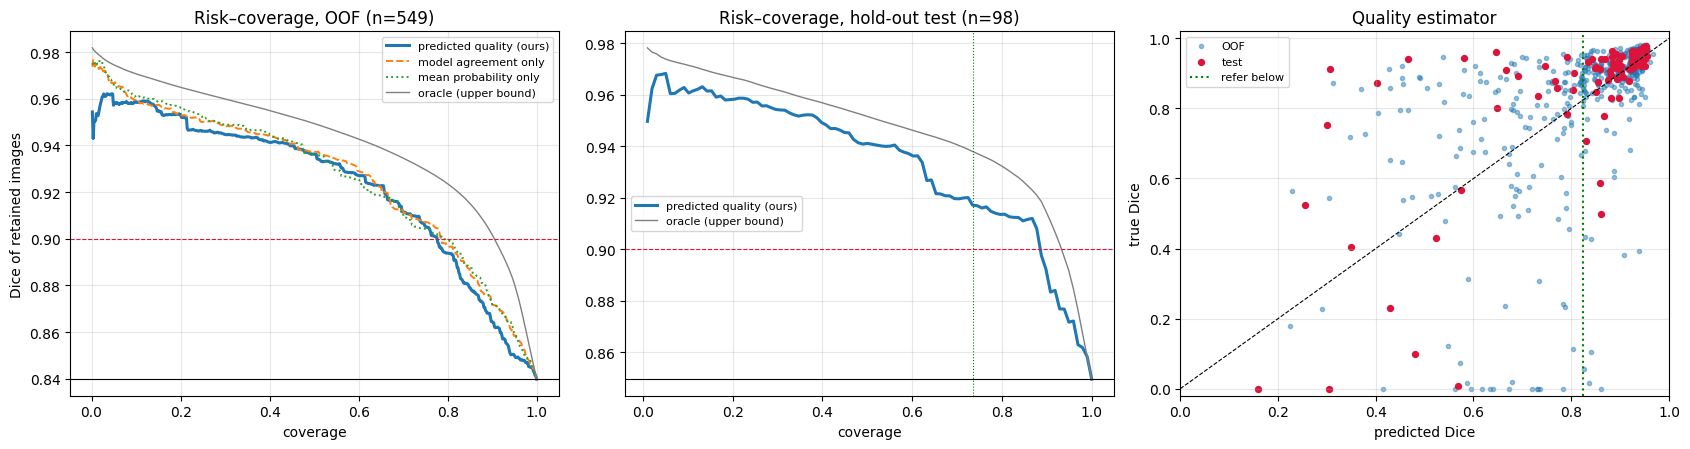

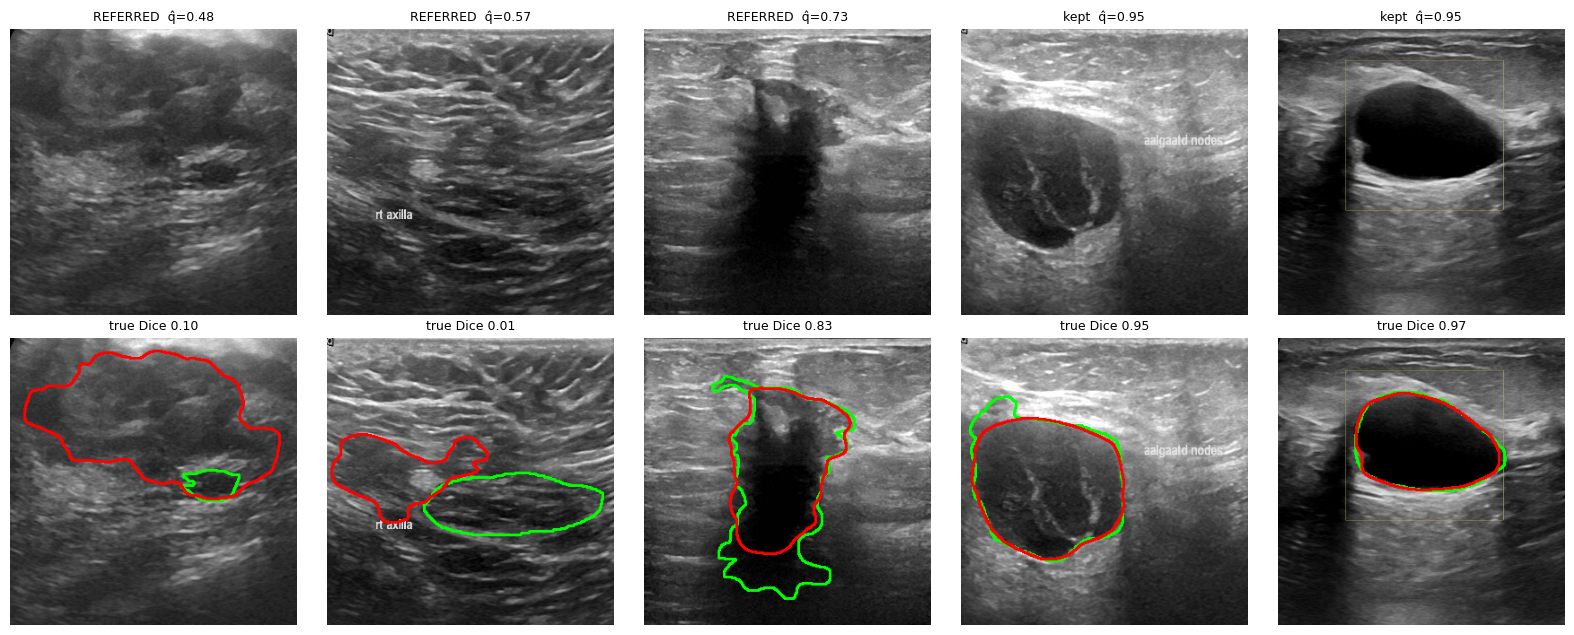

In [24]:
# Cell 11— Figures for the paper
out = CFG["out_dir"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
cov = np.arange(1, len(y_test) + 1) / len(y_test); covo = np.arange(1, len(y_oof) + 1) / len(y_oof)
ax[0].plot(covo, risk_curve(qhat_oof, y_oof), lw=2.2, label="predicted quality (ours)")
ax[0].plot(covo, risk_curve(X_oof["agree_mean"].values, y_oof), lw=1.4, ls="--", label="model agreement only")
ax[0].plot(covo, risk_curve(X_oof["mean_prob_in"].values, y_oof), lw=1.4, ls=":", label="mean probability only")
ax[0].plot(covo, risk_curve(y_oof, y_oof), lw=1, color="gray", label="oracle (upper bound)")
ax[0].axhline(y_oof.mean(), color="k", lw=.8); ax[0].axhline(CFG["target_dice"], color="crimson", lw=.8, ls="--")
ax[0].set_title("Risk–coverage, OOF (n=%d)" % len(y_oof)); ax[0].set_xlabel("coverage"); ax[0].set_ylabel("Dice of retained images")
ax[1].plot(cov, risk_curve(qhat_test, y_test), lw=2.2, label="predicted quality (ours)")
ax[1].plot(cov, risk_curve(y_test, y_test), lw=1, color="gray", label="oracle (upper bound)")
ax[1].axhline(y_test.mean(), color="k", lw=.8); ax[1].axhline(CFG["target_dice"], color="crimson", lw=.8, ls="--")
ax[1].axvline(keep_t.mean(), color="green", lw=.8, ls=":"); ax[1].set_title("Risk–coverage, hold-out test (n=%d)" % len(y_test)); ax[1].set_xlabel("coverage")
for a in ax[:2]: a.grid(alpha=.3); a.legend(fontsize=8)
ax[2].scatter(qhat_oof, y_oof, s=9, alpha=.45, label="OOF"); ax[2].scatter(qhat_test, y_test, s=18, c="crimson", label="test")
ax[2].plot([0, 1], [0, 1], "k--", lw=.8); ax[2].axvline(TAU, color="green", ls=":", label="refer below"); ax[2].set_xlim(0, 1); ax[2].set_ylim(-.02, 1.02)
ax[2].set_xlabel("predicted Dice"); ax[2].set_ylabel("true Dice"); ax[2].set_title("Quality estimator"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{out}/risk_coverage.png", dpi=300); plt.show()

# qualitative: referred vs kept (green = GT, red = prediction)
ref_idx = np.where(~keep_t)[0][:3]; kept_idx = np.where(keep_t)[0][np.argsort(-qhat_test[keep_t])[:2]]
pick = list(ref_idx) + list(kept_idx)
fig, ax = plt.subplots(2, len(pick), figsize=(3.2 * len(pick), 6.4), squeeze=False)
for c, i in enumerate(pick):
    img = cv2.resize(cv2.cvtColor(cv2.imread(test_df["img"][i]), cv2.COLOR_BGR2RGB), (S0, S0)); o = img.copy()
    for m_, col in ((TEST_MASK[i], (0, 255, 0)), (DEC_test[i], (255, 0, 0))):
        cs, _ = cv2.findContours(m_.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(o, cs, -1, col, 2)
    ax[0, c].imshow(img); ax[0, c].set_title(("REFERRED" if i in ref_idx else "kept") + f"  q̂={qhat_test[i]:.2f}", fontsize=9)
    ax[1, c].imshow(o); ax[1, c].set_title(f"true Dice {y_test[i]:.2f}", fontsize=9)
    for a in ax[:, c]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{out}/referred_vs_kept.png", dpi=300); plt.show()


In [25]:
# Cell 11b — U-Net / Attention U-Net baselines, SAME split + protocol (PyTorch, fixed schedule, last epoch)
BASE_RES = {}
if CFG["run_baselines"]:
    import torch, torch.nn as nn, torch.nn.functional as F
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu"); amp = dev.type == "cuda"; Sz = CFG["baseline_size"]

    def load_xy(df):
        X, Y = [], []
        for r in df.itertuples():
            im = cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB); m = read_mask_union(r.mask)
            X.append(cv2.resize(im, (Sz, Sz), interpolation=cv2.INTER_LINEAR)); Y.append(cv2.resize(m, (Sz, Sz), interpolation=cv2.INTER_NEAREST) > 127)
        X = (np.stack(X).astype(np.float32) / 255 - np.array([.485, .456, .406], np.float32)) / np.array([.229, .224, .225], np.float32)
        return torch.from_numpy(X).permute(0, 3, 1, 2), torch.from_numpy(np.stack(Y)).float().unsqueeze(1)

    Xtr, Ytr = load_xy(cv_df); Xte, _ = load_xy(test_df)

    class CB(nn.Sequential):
        def __init__(s, i, o): super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

    class AG(nn.Module):                     # Oktay et al. additive attention gate
        def __init__(s, fg, fl, fi):
            super().__init__(); s.wg = nn.Sequential(nn.Conv2d(fg, fi, 1), nn.BatchNorm2d(fi)); s.wx = nn.Sequential(nn.Conv2d(fl, fi, 1), nn.BatchNorm2d(fi))
            s.psi = nn.Sequential(nn.Conv2d(fi, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        def forward(s, g, x): return x * s.psi(F.relu(s.wg(g) + s.wx(x)))

    class UNet(nn.Module):
        def __init__(s, attn=False, b=32):
            super().__init__(); ch = [b, 2 * b, 4 * b, 8 * b, 16 * b]; s.attn = attn
            s.enc = nn.ModuleList([CB(3 if i == 0 else ch[i - 1], ch[i]) for i in range(5)])
            s.ag = nn.ModuleList([AG(ch[i], ch[i], max(ch[i] // 2, 8)) for i in range(4)]) if attn else None
            s.up = nn.ModuleList([nn.Conv2d(ch[i + 1], ch[i], 1) for i in range(4)]); s.dec = nn.ModuleList([CB(2 * ch[i], ch[i]) for i in range(4)])
            s.out = nn.Conv2d(b, 1, 1)
        def forward(s, x):
            f = []
            for i, e in enumerate(s.enc):
                x = e(x if i == 0 else F.max_pool2d(x, 2)); f.append(x)
            x = f[-1]
            for i in range(3, -1, -1):
                u = s.up[i](F.interpolate(x, size=f[i].shape[2:], mode="bilinear", align_corners=False))
                skip = s.ag[i](u, f[i]) if s.attn else f[i]
                x = s.dec[i](torch.cat([u, skip], 1))
            return s.out(x)

    def train_baseline(attn, seed=0):
        torch.manual_seed(seed); net = UNet(attn).to(dev); E = CFG["baseline_epochs"]
        opt = torch.optim.AdamW(net.parameters(), 1e-3, weight_decay=1e-4); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, E)
        try: sc = torch.amp.GradScaler("cuda", enabled=amp)
        except Exception: sc = torch.cuda.amp.GradScaler(enabled=amp)
        for ep in range(E):
            net.train(); perm = torch.randperm(len(Xtr)); run = 0
            for i in range(0, len(perm) - CFG["bs"] + 1, CFG["bs"]):
                ix = perm[i:i + CFG["bs"]]; x, y = Xtr[ix].to(dev), Ytr[ix].to(dev)
                if random.random() < .5: x, y = x.flip(3), y.flip(3)
                if random.random() < .3: x, y = x.flip(2), y.flip(2)
                x = x * (1 + .2 * (random.random() - .5)) + .2 * (random.random() - .5)
                with torch.autocast(device_type=dev.type, enabled=amp): lg = net(x)
                p = torch.sigmoid(lg.float()); inter = (p * y).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
                loss = F.binary_cross_entropy_with_logits(lg.float(), y) + (1 - (2 * inter + 1) / (den + 1)).mean()
                opt.zero_grad(set_to_none=True); sc.scale(loss).backward(); sc.step(opt); sc.update(); run += loss.item()
            sch.step()
            if (ep + 1) % 10 == 0 or ep == E - 1: print(f"[{'AttUNet' if attn else 'UNet'}] ep {ep+1}/{E} loss {run/max(1,len(perm)//CFG['bs']):.4f}")
        net.eval(); P = []
        with torch.no_grad():
            for i in range(0, len(Xte), CFG["bs"]):
                x = Xte[i:i + CFG["bs"]].to(dev)
                with torch.autocast(device_type=dev.type, enabled=amp):
                    p = torch.sigmoid(net(x).float()) + torch.sigmoid(net(x.flip(3)).float()).flip(3)
                P.append(F.interpolate(p / 2, size=(S0, S0), mode="bilinear", align_corners=False)[:, 0].cpu().numpy())
        del net; gc.collect(); torch.cuda.empty_cache() if amp else None
        return np.concatenate(P)

    for nm, at in (("U-Net (ours-trained)", False), ("Attention U-Net (ours-trained)", True)):
        P = train_baseline(at); BASE_RES[nm] = full_metrics(np.stack([postproc(p > .5) for p in P]), TEST_MASK)
        print(f"{nm}: test Dice {BASE_RES[nm].Dice.mean():.4f} | IoU {BASE_RES[nm].IoU.mean():.4f}")
else:
    print("baselines skipped (set CFG['run_baselines']=True to train U-Net / Attention U-Net on the same split; ~10-15 min each on a T4)")


baselines skipped (set CFG['run_baselines']=True to train U-Net / Attention U-Net on the same split; ~10-15 min each on a T4)


In [26]:
# Cell 8 (OPTIONAL) — reference evaluation of the public Keras Attention-UNet weights (/kaggle/input/breast-cancer-segmentation-attention-unet)
# READ THIS BEFORE QUOTING IT: that model was trained in a public notebook with validation_split=0.2 on an UNSHUFFLED list
# (benign, malignant, normal) -> its training set contains almost all benign + most malignant images, i.e. most of OUR hold-out test
# images.  Its score is therefore optimistic (leakage in its favour) and it is NOT a fair baseline.  The fair baselines are the
# U-Net / Attention U-Net trained with the same protocol in cell 11 (CFG["run_baselines"]=True).
H5_RES = None
if CFG["run_h5_reference"]:
    try:
        h5 = [f for d in CFG["h5_dirs"] + glob.glob("/kaggle/input/**/*attention*", recursive=True) if os.path.isdir(d)
              for f in glob.glob(os.path.join(d, "**", "*.h5"), recursive=True)]
        if not h5: raise FileNotFoundError("no .h5 file found under " + str(CFG["h5_dirs"]))
        import tensorflow as tf
        from tensorflow.keras.layers import (Layer, Conv2D, Dropout, UpSampling2D, MaxPool2D, BatchNormalization, Add, Multiply, concatenate)
        class EncoderBlock(Layer):
            def __init__(self, filters, rate, pooling=True, **kw):
                super().__init__(**kw); self.filters, self.rate, self.pooling = filters, rate, pooling
                self.c1 = Conv2D(filters, 3, padding="same", activation="relu", kernel_initializer="he_normal"); self.drop = Dropout(rate)
                self.c2 = Conv2D(filters, 3, padding="same", activation="relu", kernel_initializer="he_normal"); self.pool = MaxPool2D()
            def call(self, X):
                x = self.c2(self.drop(self.c1(X))); return (self.pool(x), x) if self.pooling else x
            def get_config(self): return {**super().get_config(), "filters": self.filters, "rate": self.rate, "pooling": self.pooling}
        class DecoderBlock(Layer):
            def __init__(self, filters, rate, **kw):
                super().__init__(**kw); self.filters, self.rate = filters, rate; self.up = UpSampling2D(); self.net = EncoderBlock(filters, rate, pooling=False)
            def call(self, X):
                X, skip = X; return self.net(concatenate([self.up(X), skip]))
            def get_config(self): return {**super().get_config(), "filters": self.filters, "rate": self.rate}
        class AttentionGate(Layer):
            def __init__(self, filters, bn, **kw):
                super().__init__(**kw); self.filters, self.bn = filters, bn
                self.normal = Conv2D(filters, 3, padding="same", activation="relu", kernel_initializer="he_normal")
                self.down = Conv2D(filters, 3, strides=2, padding="same", activation="relu", kernel_initializer="he_normal")
                self.learn = Conv2D(1, 1, padding="same", activation="sigmoid"); self.resample = UpSampling2D(); self.BN = BatchNormalization()
            def call(self, X):
                X, skip = X; x = self.resample(self.learn(Add()([self.normal(X), self.down(skip)]))); f = Multiply()([x, skip])
                return self.BN(f) if self.bn else f
            def get_config(self): return {**super().get_config(), "filters": self.filters, "bn": self.bn}
        net = tf.keras.models.load_model(h5[0], custom_objects=dict(EncoderBlock=EncoderBlock, DecoderBlock=DecoderBlock, AttentionGate=AttentionGate), compile=False)
        X = np.stack([cv2.resize(RAW[k][0], (256, 256), interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255. for k in test_df["img"]])
        P = np.concatenate([net.predict(X[i:i + 16], verbose=0)[..., 0] for i in range(0, len(X), 16)])
        P = np.stack([cv2.resize(p, (S0, S0), interpolation=cv2.INTER_LINEAR) for p in P])
        H5_RES = full_metrics(P > 0.5, TEST_MASK)
        print(f"{os.path.basename(h5[0])}: test Dice {H5_RES.Dice.mean():.4f} | IoU {H5_RES.IoU.mean():.4f}   "
              f"(REFERENCE ONLY - training split overlaps our test set; also check: predicts-all-background would give Dice≈0)")
    except Exception as e:
        print("h5 reference skipped:", type(e).__name__, str(e)[:300], "\n(not needed for the main results)")


h5 reference skipped: FileNotFoundError no .h5 file found under ['/kaggle/input/breast-cancer-segmentation-attention-unet'] 
(not needed for the main results)


In [27]:
# Cell 12 — Quantum-vs-classical ablation, paper table, honest claims, save
print("=" * 90 + "\nQUANTUM ABLATION  (same architecture/backbone/size/schedule; only the quantum channel gates differ)\n" + "=" * 90)
qa, ca = "DBU_Q_cnxt320", "DBU_cnxt320"
if qa in BANK and ca in BANK:
    rows = []
    for key, gt in (("oof", OOF_MASK), ("test", TEST_MASK)):
        dq, iq = fast_metrics(BANK[qa][key] > 0.5, gt); dc, ic = fast_metrics(BANK[ca][key] > 0.5, gt); diff = dq - dc
        try: p = wilcoxon(dq, dc).pvalue
        except Exception: p = float("nan")
        m, lo, hi = bootstrap_ci(diff); rows.append(dict(split=key.upper(), classical=round(dc.mean(), 4), quantum=round(dq.mean(), 4),
                                                         diff=round(m, 4), CI95=f"[{lo:+.4f}, {hi:+.4f}]", wilcoxon_p=round(p, 4)))
    QABL = pd.DataFrame(rows); print(QABL.to_string(index=False))
    print("-> if the CI contains 0 / p>0.05 there is NO evidence that the quantum gates improve accuracy; say so in the paper (neutral ablation).")
    QABL.to_csv(f"{CFG['out_dir']}/quantum_ablation.csv", index=False)

rows = [(n, full_metrics(BANK[n]["test"] > 0.5, TEST_MASK)) for n in STAGE1]
for n, m in BASE_RES.items(): rows.append((n, m))
if H5_RES is not None: rows.append(("[reference only, leaky] public Keras Attention-UNet .h5", H5_RES))
rows.append(("DeformBoundary-UNet bank, Caruana ensemble + post-proc [ALL images]", M_test))
tab = pd.DataFrame([dict(Method=n, Dice=m.Dice.mean(), IoU=m.IoU.mean(), Precision=m.Precision.mean(), Recall=m.Recall.mean(), HD95=m.HD95.mean(), Coverage=1.0) for n, m in rows])
sel = M_test[keep_t]
tab.loc[len(tab)] = dict(Method="Ours: ensemble + predicted-quality abstention [retained cases only]", Dice=sel.Dice.mean(), IoU=sel.IoU.mean(),
                         Precision=sel.Precision.mean(), Recall=sel.Recall.mean(), HD95=sel.HD95.mean(), Coverage=keep_t.mean())
tab = tab.round(4); print("\n" + tab.to_string(index=False))
print("""
HOW TO WORD IT (what the numbers above support)
  * Lead with the all-images row (Coverage 1.0): that is the number comparable with other BUSI papers.
  * The abstention row is a different task (segment-or-refer). Quote it only together with its coverage and referral rate.
  * Do not write 'Dice > 0.90 on BUSI' unless the all-images row says so.
  * Quantum gates: report the paired ablation above exactly as measured.
""")
tab.to_csv(f"{CFG['out_dir']}/paper_table.csv", index=False); ABL.to_csv(f"{CFG['out_dir']}/quality_estimator_ablation.csv", index=False)
RC_test.to_csv(f"{CFG['out_dir']}/risk_coverage_test.csv", index=False); RC_oof.to_csv(f"{CFG['out_dir']}/risk_coverage_oof.csv", index=False)
pd.DataFrame(dict(img=test_df.img, label=test_df.label, dice=y_test, iou=iou_test, q_hat=qhat_test, referred=~keep_t, near_dup=NEAR_DUP_TEST)).to_csv(f"{CFG['out_dir']}/test_per_image.csv", index=False)
json.dump(dict(all_images=dict(dice=float(y_test.mean()), iou=float(iou_test.mean())), selective=dict(dice=float(sel.Dice.mean()), iou=float(sel.IoU.mean()), coverage=float(keep_t.mean()), tau=TAU),
               oof=dict(dice=float(y_oof.mean()), iou=float(iou_oof.mean())), threshold=THR, weights=W2), open(f"{CFG['out_dir']}/results.json", "w"), indent=2, default=float)
print("saved ->", sorted(os.listdir(CFG["out_dir"])))


QUANTUM ABLATION  (same architecture/backbone/size/schedule; only the quantum channel gates differ)
split  classical  quantum    diff               CI95  wilcoxon_p
  OOF     0.8330   0.8314 -0.0016 [-0.0103, +0.0070]      0.3933
 TEST     0.8475   0.8514  0.0039 [-0.0028, +0.0132]      0.2114
-> if the CI contains 0 / p>0.05 there is NO evidence that the quantum gates improve accuracy; say so in the paper (neutral ablation).

                                                             Method   Dice    IoU  Precision  Recall    HD95  Coverage
                                                      DBU_Q_cnxt320 0.8514 0.7799     0.8657  0.8605 25.2018    1.0000
                                                        DBU_cnxt320 0.8475 0.7764     0.8606  0.8585 30.3612    1.0000
                                                      DBU_Q_cnxs384 0.8492 0.7790     0.8584  0.8689 29.4077    1.0000
DeformBoundary-UNet bank, Caruana ensemble + post-proc [ALL images] 0.8496 0.7801     0.8608 